In [1]:

!pip -q install nltk scikit-learn pandas matplotlib seaborn gradio networkx

import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import gradio as gr

from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

dataset = {
    "symptoms": [
        "What are the symptoms of diabetes?",
        "What are common signs of diabetes?",
        "How can I recognize diabetes symptoms?",
        "Does diabetes cause frequent urination?",
        "Why do diabetic patients feel thirsty?",
        "Can unexplained weight loss indicate diabetes?"
    ],
    "causes": [
        "What causes diabetes?",
        "Why does diabetes develop?",
        "What causes type 2 diabetes?",
        "Is diabetes caused by insulin resistance?",
        "Can genetics contribute to diabetes?",
        "What factors lead to diabetes?"
    ],
    "risk_factors": [
        "Who is at risk of diabetes?",
        "What are diabetes risk factors?",
        "Does obesity increase diabetes risk?",
        "Can family history increase diabetes risk?",
        "Does physical inactivity increase diabetes risk?",
        "Who is more likely to develop type 2 diabetes?"
    ],
    "diagnosis": [
        "How is diabetes diagnosed?",
        "What tests detect diabetes?",
        "What is an HbA1c test?",
        "How does a fasting blood glucose test work?",
        "What blood sugar level indicates diabetes?",
        "Can a glucose tolerance test diagnose diabetes?"
    ],
    "medication": [
        "What medicines treat diabetes?",
        "What is metformin used for?",
        "How does insulin help diabetic patients?",
        "What medications control blood sugar?",
        "Can diabetes be treated with tablets?",
        "What drugs are prescribed for type 2 diabetes?"
    ],
    "diet": [
        "What foods should diabetic patients eat?",
        "What is a healthy diabetes diet?",
        "Should diabetic people avoid sugary drinks?",
        "Which foods help manage blood glucose?",
        "Can diabetic patients eat fruit?",
        "How does carbohydrate intake affect diabetes?"
    ],
    "exercise": [
        "What exercises are good for diabetes?",
        "Does walking help control blood sugar?",
        "How much physical activity is recommended for diabetes?",
        "Can exercise improve insulin sensitivity?",
        "Is cycling beneficial for diabetic patients?",
        "How does regular exercise help diabetes?"
    ],
    "monitoring": [
        "How should I monitor blood sugar?",
        "What is continuous glucose monitoring?",
        "How often should glucose be checked?",
        "How does a glucometer work?",
        "What is the target blood glucose range?",
        "Why is regular glucose monitoring important?"
    ],
    "complications": [
        "What complications can diabetes cause?",
        "Can diabetes damage the kidneys?",
        "Does diabetes affect eyesight?",
        "How does diabetes cause nerve damage?",
        "Can diabetes lead to heart disease?",
        "What are long term complications of diabetes?"
    ],
    "prevention": [
        "How can type 2 diabetes be prevented?",
        "What lifestyle changes reduce diabetes risk?",
        "Can maintaining a healthy weight prevent diabetes?",
        "Does regular exercise help prevent type 2 diabetes?",
        "How can I lower my risk of developing diabetes?",
        "Can healthy eating reduce diabetes risk?"
    ]
}

df = pd.DataFrame(
    [(query, intent) for intent, queries in dataset.items() for query in queries],
    columns=["query", "intent"]
)

print("Total queries:", len(df))
print("Total intents:", df["intent"].nunique())
print(df["intent"].value_counts())
display(df.head(10))


Total queries: 60
Total intents: 10
intent
symptoms         6
causes           6
risk_factors     6
diagnosis        6
medication       6
diet             6
exercise         6
monitoring       6
complications    6
prevention       6
Name: count, dtype: int64


,query,intent
0,What are the symptoms of diabetes?,symptoms
1,What are common signs of diabetes?,symptoms
2,How can I recognize diabetes symptoms?,symptoms
3,Does diabetes cause frequent urination?,symptoms
4,Why do diabetic patients feel thirsty?,symptoms
5,Can unexplained weight loss indicate diabetes?,symptoms
6,What causes diabetes?,causes
7,Why does diabetes develop?,causes
8,What causes type 2 diabetes?,causes
9,Is diabetes caused by insulin resistance?,causes


In [5]:

taxonomy = {
    "Diabetes Fundamentals": {
        "Symptoms": "symptoms",
        "Causes": "causes",
        "Risk Factors": "risk_factors"
    },
    "Clinical Care": {
        "Diagnosis": "diagnosis",
        "Medication": "medication"
    },
    "Lifestyle Management": {
        "Diet": "diet",
        "Exercise": "exercise",
        "Prevention": "prevention"
    },
    "Long-Term Management": {
        "Glucose Monitoring": "monitoring",
        "Complications": "complications"
    }
}

for category, subcategories in taxonomy.items():
    print(f"\n{category}")
    for subcategory, intent in subcategories.items():
        print(f"  |-- {subcategory} ({intent})")



Diabetes Fundamentals
  |-- Symptoms (symptoms)
  |-- Causes (causes)
  |-- Risk Factors (risk_factors)

Clinical Care
  |-- Diagnosis (diagnosis)
  |-- Medication (medication)

Lifestyle Management
  |-- Diet (diet)
  |-- Exercise (exercise)
  |-- Prevention (prevention)

Long-Term Management
  |-- Glucose Monitoring (monitoring)
  |-- Complications (complications)


Concepts: 15
Relationships: 12


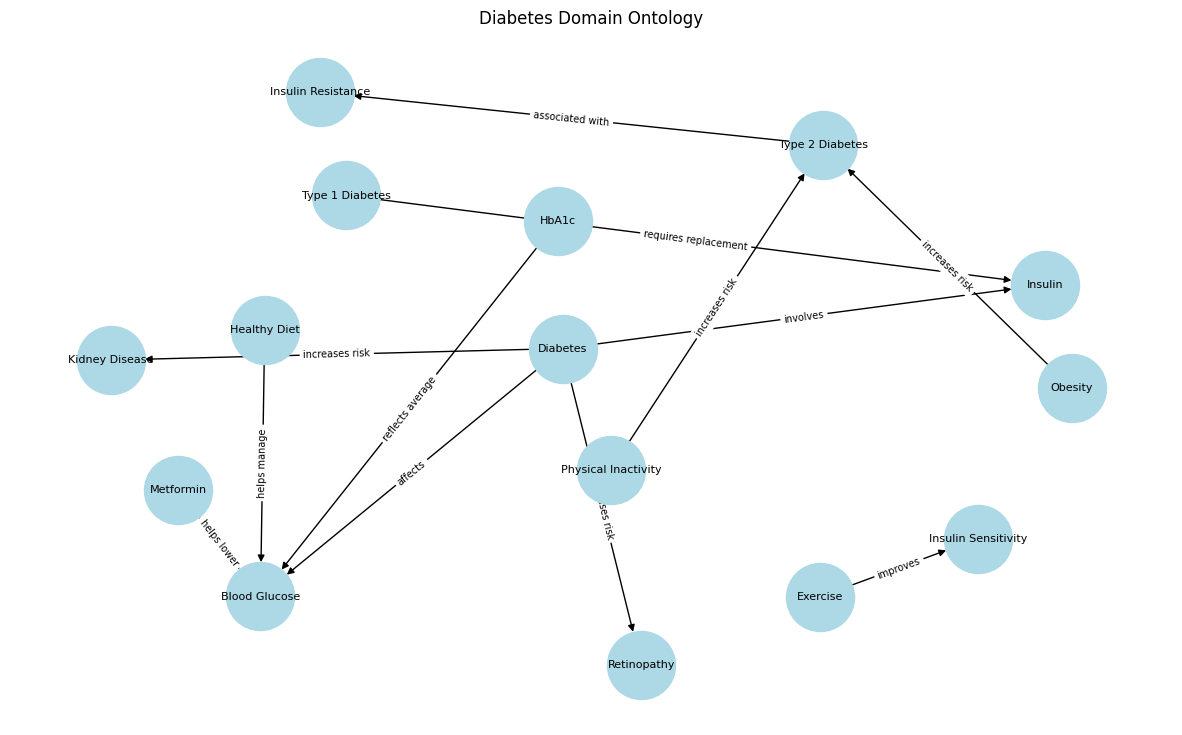

In [6]:

relationships = [
    ("Diabetes", "Insulin", "involves"),
    ("Diabetes", "Blood Glucose", "affects"),
    ("Type 1 Diabetes", "Insulin", "requires replacement"),
    ("Type 2 Diabetes", "Insulin Resistance", "associated with"),
    ("Obesity", "Type 2 Diabetes", "increases risk"),
    ("Physical Inactivity", "Type 2 Diabetes", "increases risk"),
    ("Healthy Diet", "Blood Glucose", "helps manage"),
    ("Exercise", "Insulin Sensitivity", "improves"),
    ("Metformin", "Blood Glucose", "helps lower"),
    ("HbA1c", "Blood Glucose", "reflects average"),
    ("Diabetes", "Kidney Disease", "increases risk"),
    ("Diabetes", "Retinopathy", "increases risk")
]

G = nx.DiGraph()

for source, target, relation in relationships:
    G.add_edge(source, target, relation=relation)

print("Concepts:", G.number_of_nodes())
print("Relationships:", G.number_of_edges())

plt.figure(figsize=(15, 9))
pos = nx.spring_layout(G, seed=42, k=1.5)

nx.draw_networkx(
    G, pos,
    node_color="lightblue",
    node_size=2400,
    font_size=8,
    arrows=True
)

edge_labels = nx.get_edge_attributes(G, "relation")
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=edge_labels, font_size=7
)

plt.title("Diabetes Domain Ontology")
plt.axis("off")
plt.show()


In [7]:

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    # 1. Lowercase conversion
    text = text.lower()

    # 2. Remove punctuation
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # 3. Tokenization
    tokens = word_tokenize(text)

    # 4. Stopword removal
    tokens = [
        token for token in tokens
        if token not in stop_words
    ]

    # 5. Lemmatization
    tokens = [
        lemmatizer.lemmatize(token, pos="v")
        for token in tokens
    ]

    return " ".join(tokens)

df["processed_query"] = df["query"].apply(preprocess)

display(df[["query", "processed_query", "intent"]].head(10))


,query,processed_query,intent
0,What are the symptoms of diabetes?,symptoms diabetes,symptoms
1,What are common signs of diabetes?,common sign diabetes,symptoms
2,How can I recognize diabetes symptoms?,recognize diabetes symptoms,symptoms
3,Does diabetes cause frequent urination?,diabetes cause frequent urination,symptoms
4,Why do diabetic patients feel thirsty?,diabetic patients feel thirsty,symptoms
5,Can unexplained weight loss indicate diabetes?,unexplained weight loss indicate diabetes,symptoms
6,What causes diabetes?,cause diabetes,causes
7,Why does diabetes develop?,diabetes develop,causes
8,What causes type 2 diabetes?,cause type 2 diabetes,causes
9,Is diabetes caused by insulin resistance?,diabetes cause insulin resistance,causes


In [8]:

X = df["processed_query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Model training completed!
Training samples: 48
Testing samples: 12


Accuracy : 0.6667
Precision: 0.5833
Recall   : 0.6667
F1-score : 0.6111

Classification Report:
               precision    recall  f1-score   support

       causes       0.50      1.00      0.67         1
complications       0.00      0.00      0.00         1
    diagnosis       1.00      1.00      1.00         1
         diet       0.50      0.50      0.50         2
     exercise       0.00      0.00      0.00         1
   medication       0.00      0.00      0.00         1
   monitoring       1.00      1.00      1.00         2
   prevention       0.50      1.00      0.67         1
 risk_factors       1.00      1.00      1.00         1
     symptoms       1.00      1.00      1.00         1

     accuracy                           0.67        12
    macro avg       0.55      0.65      0.58        12
 weighted avg       0.58      0.67      0.61        12



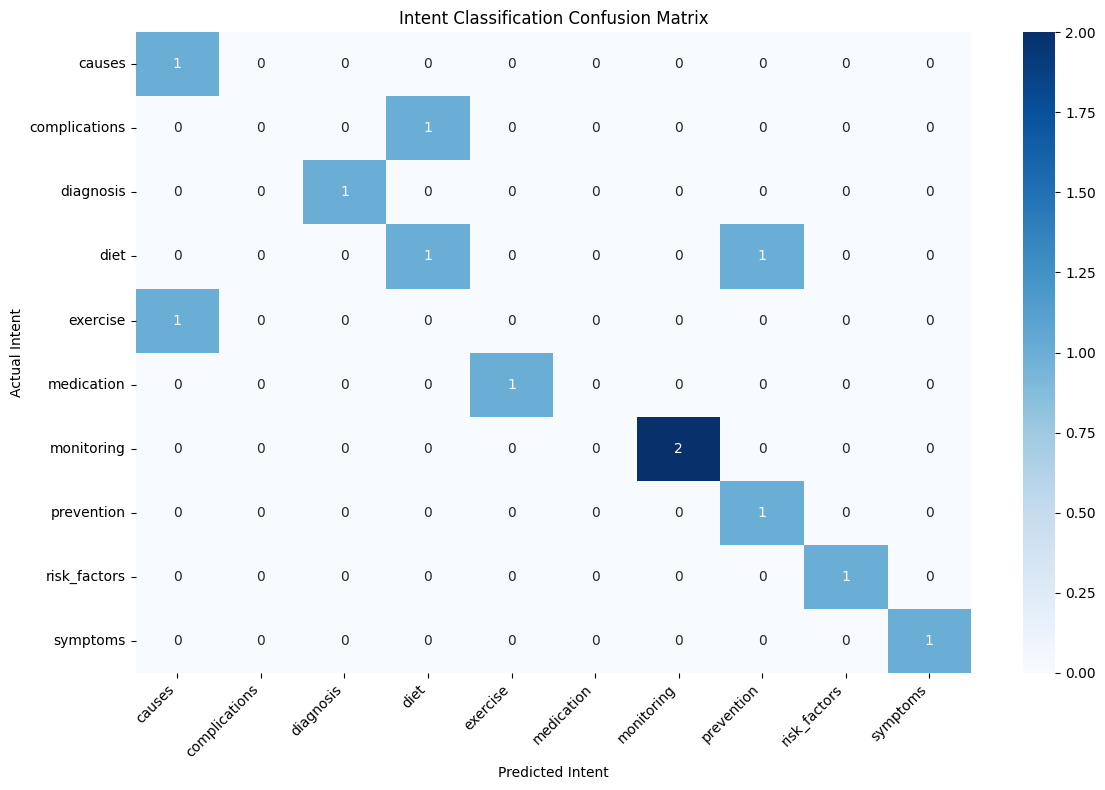

In [9]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Intent Classification Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [10]:

knowledge_base = {
    "symptoms": (
        "Common diabetes symptoms include frequent urination, "
        "increased thirst, unexplained weight loss, fatigue, "
        "blurred vision and slow-healing wounds. "
        "Some people with type 2 diabetes have no noticeable symptoms."
    ),

    "causes": (
        "Diabetes develops when the body cannot produce enough insulin "
        "or cannot use insulin effectively. Type 1 diabetes is usually "
        "caused by autoimmune destruction of insulin-producing cells. "
        "Type 2 diabetes involves insulin resistance and progressive "
        "impairment of insulin production."
    ),

    "risk_factors": (
        "Risk factors for type 2 diabetes include excess body weight, "
        "physical inactivity, family history, increasing age, "
        "prediabetes and a history of gestational diabetes. "
        "Type 1 diabetes has different risk factors."
    ),

    "diagnosis": (
        "Diabetes can be diagnosed using HbA1c, fasting plasma glucose, "
        "an oral glucose tolerance test or random plasma glucose "
        "with classic symptoms. Common diagnostic thresholds include "
        "HbA1c >= 6.5% and fasting plasma glucose >= 126 mg/dL. "
        "Confirmation is generally required unless hyperglycemia "
        "is unequivocal. A clinician should interpret the results."
    ),

    "medication": (
        "Diabetes treatments may include insulin, metformin, "
        "GLP-1 receptor agonists and SGLT2 inhibitors, depending "
        "on diabetes type and individual medical needs. "
        "People with type 1 diabetes require insulin. "
        "Medication selection and dosage require professional guidance."
    ),

    "diet": (
        "A diabetes-friendly eating pattern generally emphasizes "
        "vegetables, whole grains, legumes, appropriate portions "
        "of fruit, lean proteins and unsaturated fats. "
        "Limiting sugary drinks and managing carbohydrate portions "
        "can help regulate blood glucose."
    ),

    "exercise": (
        "Regular physical activity can improve insulin sensitivity "
        "and blood glucose management. Many adults with diabetes "
        "are advised to aim for at least 150 minutes of moderate "
        "aerobic activity weekly, alongside resistance training, "
        "when medically appropriate. Exercise plans should account "
        "for hypoglycemia risk and complications."
    ),

    "monitoring": (
        "Blood glucose can be monitored using a glucometer or "
        "continuous glucose monitor (CGM). Common premeal targets "
        "for many nonpregnant adults are 80-130 mg/dL, but targets "
        "must be individualized. HbA1c reflects average glucose "
        "over approximately 2-3 months."
    ),

    "complications": (
        "Long-term diabetes complications may include kidney disease, "
        "retinopathy, neuropathy, cardiovascular disease and foot "
        "problems. Regular screening, glucose management and control "
        "of blood pressure and cholesterol can reduce risks."
    ),

    "prevention": (
        "Type 2 diabetes risk can often be reduced through regular "
        "physical activity, balanced nutrition, weight management "
        "when appropriate and avoiding tobacco. People with "
        "prediabetes may benefit from structured lifestyle programs. "
        "Type 1 diabetes generally cannot be prevented through "
        "ordinary lifestyle changes."
    )
}

print("Knowledge base entries:", len(knowledge_base))


Knowledge base entries: 10


In [11]:

CONFIDENCE_THRESHOLD = 0.30

emergency_patterns = [
    r"\bunconscious\b",
    r"\bnot breathing\b",
    r"\bseizure\b",
    r"\bsevere chest pain\b",
    r"\bchest pain.*shortness of breath\b",
    r"\bshortness of breath.*chest pain\b",
    r"\bdiabetic ketoacidosis\b",
    r"\bfruity breath.*vomit",
    r"\bvomit.*fruity breath",
    r"\bconfus(?:ed|ion).*vomit",
    r"\bvomit.*confus(?:ed|ion)"
]

hypoglycemia_patterns = [
    r"\blow blood sugar\b",
    r"\bhypoglycemi\w*\b",
    r"\bglucose (?:is |of |at )?(?:below|under)\s*70\b",
    r"\bblood sugar (?:is |of |at )?(?:below|under)\s*70\b"
]

unsupported_patterns = [
    r"\b(cancer|asthma|migraine|arthritis|dengue|malaria)\b",
    r"\b(heart attack|pneumonia|thyroid)\b"
]

personal_diagnosis_patterns = [
    r"\bdo i have diabetes\b",
    r"\bam i diabetic\b",
    r"\bdiagnose me\b"
]

medication_safety_patterns = [
    r"\bhow much (?:insulin|metformin)\b",
    r"\bwhat dose\b",
    r"\bchange my dose\b",
    r"\bstop taking\b",
    r"\bdouble my dose\b"
]

def matches_any(text, patterns):
    return any(re.search(pattern, text) for pattern in patterns)

def predict_intent(query):
    processed = preprocess(query)
    probabilities = model.predict_proba([processed])[0]
    index = np.argmax(probabilities)

    intent = model.classes_[index]
    confidence = float(probabilities[index])

    return intent, confidence

def healthcare_assistant(query):
    query = query.strip()

    if not query:
        return "Please enter a healthcare question.", "empty", 0.0

    text = query.lower()

    # Rule 1: Emergency escalation
    if matches_any(text, emergency_patterns):
        return (
            "EMERGENCY: These symptoms may indicate a serious medical "
            "emergency. Call your local emergency number immediately "
            "(112 in India). Do not delay emergency care to use this chatbot.",
            "emergency", 1.0
        )

    # Rule 2: Hypoglycemia safety
    if matches_any(text, hypoglycemia_patterns):
        return (
            "Low blood glucose (below 70 mg/dL) needs prompt attention. "
            "If the person is awake and able to swallow, a common "
            "approach is 15 grams of fast-acting carbohydrate, followed "
            "by a glucose recheck after 15 minutes. Repeat if still low. "
            "If unconscious, having a seizure or unable to swallow, "
            "do not give food or drink by mouth. Use prescribed "
            "glucagon if available and call emergency services.",
            "hypoglycemia_safety", 1.0
        )

    # Rule 3: Unsupported healthcare queries
    if matches_any(text, unsupported_patterns):
        return (
            "This assistant specializes in diabetes care information. "
            "Your question appears to concern another medical condition. "
            "Please consult an appropriate healthcare professional.",
            "unsupported", 0.0
        )

    # Rule 4: Personalized diagnosis restriction
    if matches_any(text, personal_diagnosis_patterns):
        return (
            "I cannot determine whether you have diabetes. "
            "Diagnosis requires appropriate laboratory testing "
            "and clinical assessment. Please consult a clinician.",
            "diagnosis_safety", 1.0
        )

    # Rule 5: Medication safety
    if matches_any(text, medication_safety_patterns):
        return (
            "Medication doses must be individualized. Do not start, "
            "stop or change insulin or other diabetes medication "
            "without advice from your prescribing clinician.",
            "medication_safety", 1.0
        )

    intent, confidence = predict_intent(query)

    # Rule 6: Low-confidence handling
    if confidence < CONFIDENCE_THRESHOLD:
        return (
            "I am not confident that I understood your question. "
            "Please rephrase it using diabetes-related terms, "
            "such as symptoms, diet, diagnosis or glucose monitoring.",
            "low_confidence", confidence
        )

    # Rule 7: Knowledge retrieval
    response = knowledge_base.get(intent)

    if response is None:
        return (
            "I do not have verified information for this topic.",
            "unsupported", confidence
        )

    return response, intent, confidence

print("Rule-based reasoning engine initialized.")


Rule-based reasoning engine initialized.


In [12]:

test_queries = [
    # One query for every intent
    "What are the symptoms of diabetes?",
    "What causes diabetes?",
    "Who is at risk of diabetes?",
    "How is diabetes diagnosed?",
    "What medicines treat diabetes?",
    "What foods should diabetic patients eat?",
    "What exercises are good for diabetes?",
    "How should I monitor blood sugar?",
    "What complications can diabetes cause?",
    "How can type 2 diabetes be prevented?",

    # Differently worded query
    "Why am I always thirsty and urinating frequently?",

    # Unsupported healthcare query
    "How is asthma treated?",

    # Low-confidence query
    "quantum spaceship banana galaxy",

    # Emergency query
    "A diabetic person is unconscious and not breathing",

    # Medication safety
    "Should I double my dose of metformin?"
]

results = []

for query in test_queries:
    response, intent, confidence = healthcare_assistant(query)

    results.append({
        "Query": query,
        "Detected Intent": intent,
        "Confidence": round(confidence, 3),
        "Response": response
    })

test_df = pd.DataFrame(results)
display(test_df)

# Explicit checks for safety and fallback rules
assert healthcare_assistant(
    "A diabetic person is unconscious"
)[1] == "emergency"

assert healthcare_assistant(
    "How is asthma treated?"
)[1] == "unsupported"

assert healthcare_assistant(
    "Should I double my dose of metformin?"
)[1] == "medication_safety"

print("Core rule tests passed.")


,Query,Detected Intent,Confidence,Response
0,What are the symptoms of diabetes?,low_confidence,0.150,I am not confident that I understood your ques...
1,What causes diabetes?,low_confidence,0.223,I am not confident that I understood your ques...
2,Who is at risk of diabetes?,low_confidence,0.245,I am not confident that I understood your ques...
3,How is diabetes diagnosed?,low_confidence,0.223,I am not confident that I understood your ques...
4,What medicines treat diabetes?,low_confidence,0.233,I am not confident that I understood your ques...
5,What foods should diabetic patients eat?,low_confidence,0.247,I am not confident that I understood your ques...
6,What exercises are good for diabetes?,low_confidence,0.231,I am not confident that I understood your ques...
7,How should I monitor blood sugar?,low_confidence,0.261,I am not confident that I understood your ques...
8,What complications can diabetes cause?,low_confidence,0.272,I am not confident that I understood your ques...
9,How can type 2 diabetes be prevented?,low_confidence,0.154,I am not confident that I understood your ques...


Core rule tests passed.


In [13]:

def chat_response(message, history):
    response, intent, confidence = healthcare_assistant(message)

    return (
        f"{response}\n\n"
        f"---\n"
        f"**Detected Intent:** {intent}\n\n"
        f"**Confidence:** {confidence:.2%}"
    )

demo = gr.ChatInterface(
    fn=chat_response,
    title="Diabetes Care Cognitive Assistant",
    description=(
        "Ask questions about diabetes symptoms, causes, "
        "diagnosis, medications, diet, exercise, monitoring, "
        "complications and prevention. "
        "Educational information only; not a substitute "
        "for professional medical advice."
    ),
    examples=[
        "What are the symptoms of diabetes?",
        "What foods should diabetic patients eat?",
        "How is diabetes diagnosed?",
        "Can diabetes damage the kidneys?",
        "How can I prevent type 2 diabetes?",
        "A diabetic person is unconscious"
    ]
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://807243b64161499a3d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
